# Классификация

Содержание:
1. Описание датасета и подготовка данных
2. Логистическая регрессия
3. Многослойный перцептрон
4. Дерево решений
5. Выводы

### 1. Датасет и подготовка данных

В качестве датасета взят тот же датасет, что и для линейной регрессии

Описание датасета: https://archive.ics.uci.edu/dataset/45/heart+disease

Цель работы: обучить несколько моделей классификации и оценить их качество

Целевая переменная: target - наличие заболевания (приведенная к значениям 0 (нет болезни) и 1 (есть болезнть))


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [2]:
# Загрузка датасета
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
columns = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"]
data = pd.read_csv(url, names=columns, na_values="?")
data.dropna(inplace=True)  # Удаляем строки с пропущенными значениями
data["target"] = (data["target"] > 0).astype(int)  # Бинаризуем переменную, отвечающее за наличие болезни
X = data.drop(columns=['target'])
y = data['target']

data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
# В качестве размера тестовой выборки было выбрано 25%
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25)

In [4]:
# Масштабирование данных: подбор параметров для масштабирования проводится на обучающей выборке,
# само масштабирование — на обоих
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 2. Логистическая регрессия

In [5]:
# Обучим модель логистической регресии на масштабированных обучающих данных
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [6]:
# Предсказания
y_pred = model.predict(X_test_scaled)

# Оценка качества модели
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.2f}')
print(classification_report(y_test, y_pred))

Accuracy: 0.84
              precision    recall  f1-score   support

           0       0.84      0.91      0.87        45
           1       0.85      0.73      0.79        30

    accuracy                           0.84        75
   macro avg       0.84      0.82      0.83        75
weighted avg       0.84      0.84      0.84        75



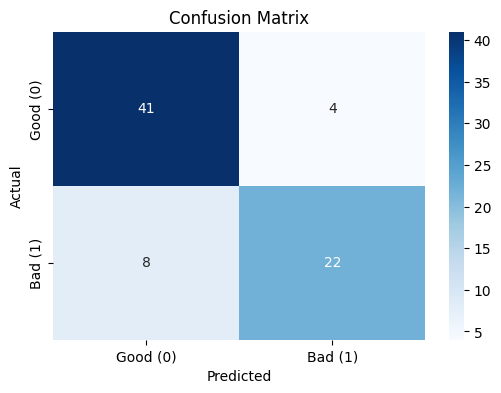

In [7]:
# Матрица ошибок модели на тестовой выборке
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', xticklabels=['Good (0)', 'Bad (1)'], yticklabels=['Good (0)', 'Bad (1)'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

### 3. Многослойный перцептрон

В качестве эксперимента, сделаем перебор параметров модели в цикле

Заранее определим ограничения:
1. Рассмотрим модели с 3 скрытыми слоями
2. Максимум нейронов в каждом слое - 5

In [8]:
t = []

for a in range(1, 6):
    for b in range(1, 6):
        for c in range(1, 6):
            mlp_model = MLPClassifier(hidden_layer_sizes=(a, b, c),
                        activation='relu',    # Выберем relu в качестве функции активации
                        solver='adam', 
                        max_iter=1000)
            mlp_model.fit(X_train_scaled, y_train)

            y_pred_mlp = mlp_model.predict(X_test_scaled)
            accuracy_mlp = accuracy_score(y_test, y_pred_mlp)
           
            t.append({
                'layer_1': a,
                'layer_2': b,
                'layer_3': c,
                'accuracy': accuracy_mlp
            })

df_mlp = pd.DataFrame(t)  
df_mlp.head()        

C:\Users\Максим\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\Максим\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\Максим\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\М

,layer_1,layer_2,layer_3,accuracy
0,1,1,1,0.600000
1,1,1,2,0.813333
2,1,1,3,0.400000
3,1,1,4,0.600000
4,1,1,5,0.800000


C:\Users\Максим\AppData\Local\Temp\ipykernel_5980\520531798.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='architecture', y='accuracy', data=top_results, palette='viridis')


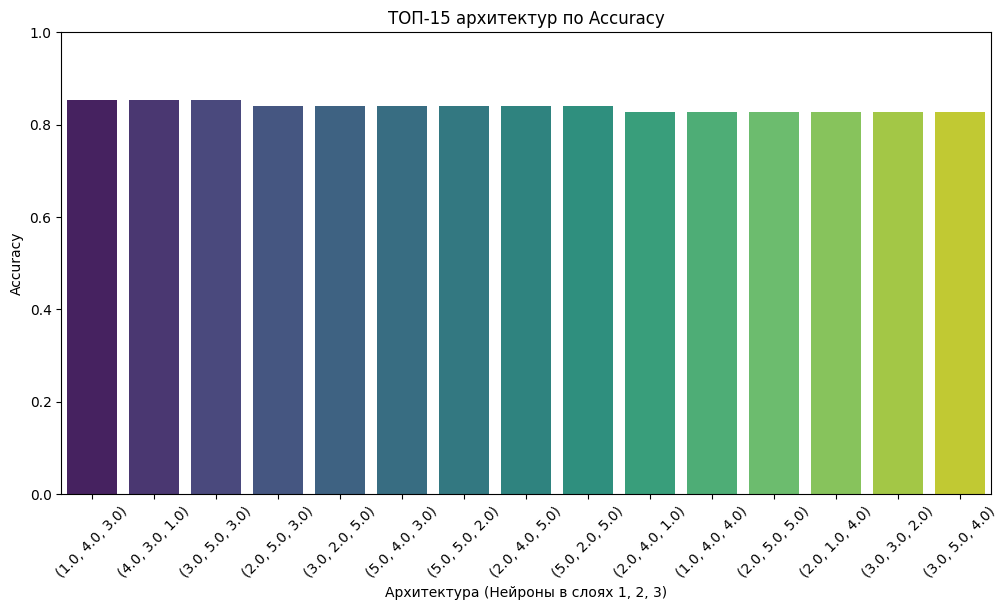

In [9]:
# Берем топ-15 лучших результатов
top_results = df_mlp.sort_values(by='accuracy', ascending=False).head(15)
top_results['architecture'] = top_results.apply(lambda row: f"({row['layer_1']}, {row['layer_2']}, {row['layer_3']})", axis=1)

plt.figure(figsize=(12, 6))
sns.barplot(x='architecture', y='accuracy', data=top_results, palette='viridis')
plt.title('ТОП-15 архитектур по Accuracy')
plt.xlabel('Архитектура (Нейроны в слоях 1, 2, 3)')
plt.ylabel('Accuracy')
plt.xticks(rotation=45)
plt.ylim(0, 1) # Чтобы график был в пределах от 0 до 1
plt.show()

In [33]:
# Берем модель со структурой скрытых слоев по графику

mlp_model = MLPClassifier(hidden_layer_sizes=(3, 5, 3),
                         activation='logistic', 
                         solver='adam', 
                         max_iter=1000)
mlp_model.fit(X_train_scaled, y_train)

C:\Users\Максим\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


,hidden_layer_sizes,"(3, ...)"
,activation,'logistic'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,1000
,shuffle,True
,random_state,None


In [34]:
# Предсказания для MLP
y_pred_mlp = mlp_model.predict(X_test_scaled)

# Оценка качества модели
accuracy_mlp = accuracy_score(y_test, y_pred_mlp)
precision_mlp = precision_score(y_test, y_pred_mlp)
recall_mlp = recall_score(y_test, y_pred_mlp)
f1_mlp = f1_score(y_test, y_pred_mlp)
print(f'MLP Accuracy: {accuracy_mlp:.2f}')
print(f'MLP Precision: {precision_mlp:.2f}')
print(f'MLP Recall: {recall_mlp:.2f}')
print(f'MLP F1 Score: {f1_mlp:.2f}')
print(classification_report(y_test, y_pred_mlp))

MLP Accuracy: 0.80
MLP Precision: 0.80
MLP Recall: 0.67
MLP F1 Score: 0.73
              precision    recall  f1-score   support

           0       0.80      0.89      0.84        45
           1       0.80      0.67      0.73        30

    accuracy                           0.80        75
   macro avg       0.80      0.78      0.78        75
weighted avg       0.80      0.80      0.80        75



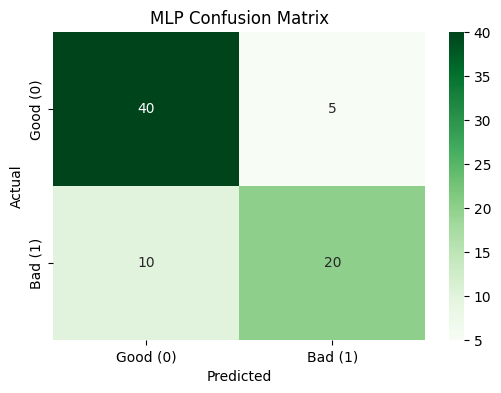

In [35]:
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_mlp), annot=True, fmt='d', cmap='Greens', xticklabels=['Good (0)', 'Bad (1)'], yticklabels=['Good (0)', 'Bad (1)'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('MLP Confusion Matrix')
plt.show()

### 4. Дерево решений

#### 4.1 Без ограничения глубины

In [38]:
dt_model = DecisionTreeClassifier()
dt_model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [39]:
y_pred_dt = dt_model.predict(X_test)

# Оценка качества модели
accuracy_dt = accuracy_score(y_test, y_pred_dt)
print(f'Decision Tree Accuracy: {accuracy_dt:.2f}')
print(classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 0.69
              precision    recall  f1-score   support

           0       0.75      0.73      0.74        45
           1       0.61      0.63      0.62        30

    accuracy                           0.69        75
   macro avg       0.68      0.68      0.68        75
weighted avg       0.70      0.69      0.69        75



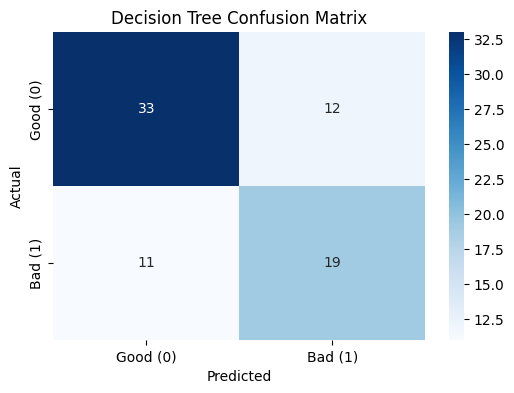

In [40]:
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt='d', cmap='Blues', xticklabels=['Good (0)', 'Bad (1)'], yticklabels=['Good (0)', 'Bad (1)'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Decision Tree Confusion Matrix')
plt.show()

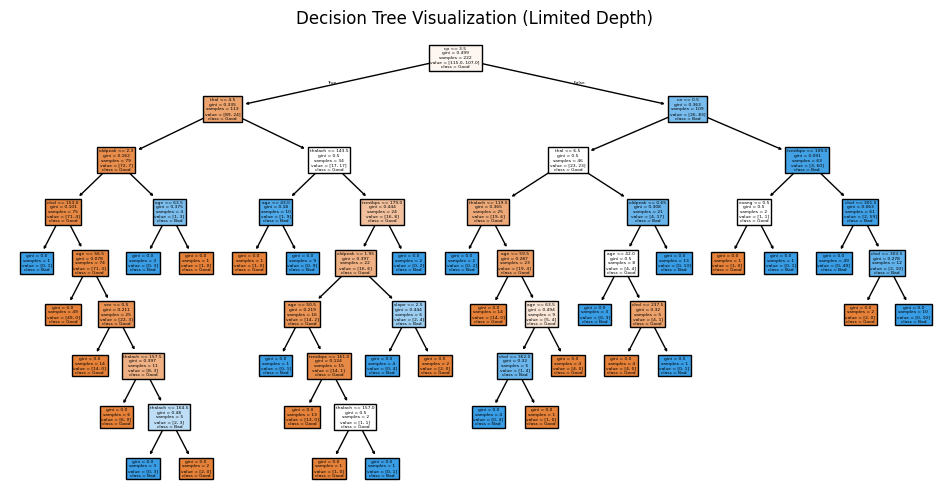

In [41]:
plt.figure(figsize=(12, 6))
plot_tree(dt_model, feature_names=X.columns, class_names=['Good', 'Bad'], filled=True)
plt.title('Decision Tree Visualization (Limited Depth)')
plt.show()

#### 4.2 С ограничением глубины

In [42]:
# Возьмем глубину равную 3
max_depth = 3
dt_model_limited = DecisionTreeClassifier(max_depth=max_depth)
dt_model_limited.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [43]:
y_pred_dt_limited = dt_model_limited.predict(X_test)

# Оценка качества модели
accuracy_dt = accuracy_score(y_test, y_pred_dt_limited)
print(f'Decision Tree Accuracy: {accuracy_dt:.2f}')
print(classification_report(y_test, y_pred_dt_limited))

Decision Tree Accuracy: 0.75
              precision    recall  f1-score   support

           0       0.74      0.89      0.81        45
           1       0.76      0.53      0.63        30

    accuracy                           0.75        75
   macro avg       0.75      0.71      0.72        75
weighted avg       0.75      0.75      0.74        75



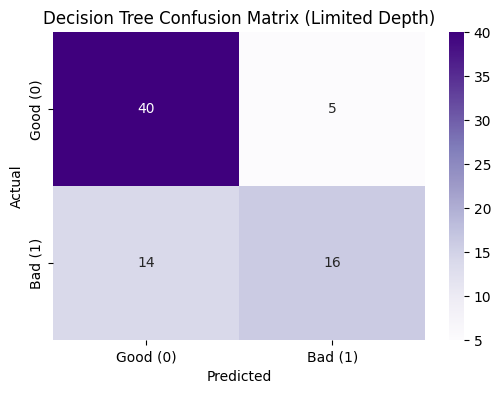

In [44]:
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_dt_limited), annot=True, fmt='d', cmap='Purples', xticklabels=['Good (0)', 'Bad (1)'], yticklabels=['Good (0)', 'Bad (1)'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Decision Tree Confusion Matrix (Limited Depth)')
plt.show()


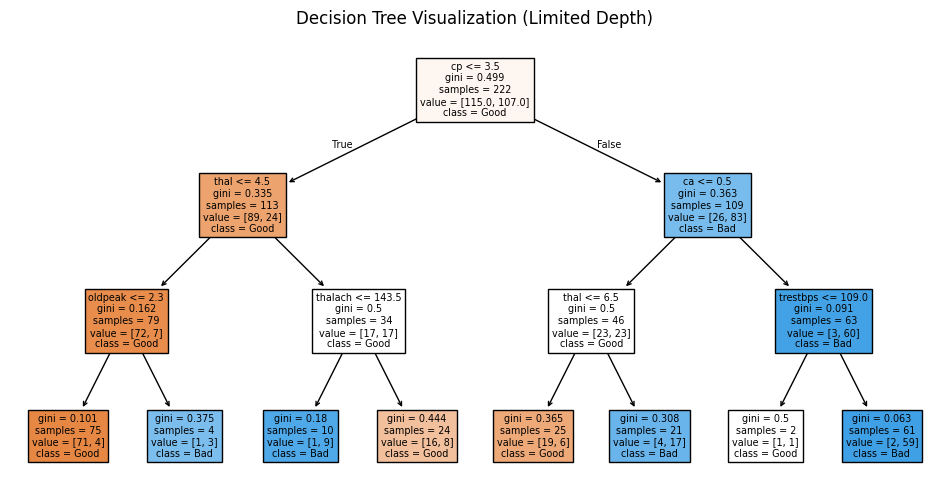

In [45]:
# Визуализация ограниченного дерева решений
plt.figure(figsize=(12, 6))
plot_tree(dt_model_limited, feature_names=X.columns, class_names=['Good', 'Bad'], filled=True, max_depth=3)
plt.title('Decision Tree Visualization (Limited Depth)')
plt.show()


### 5. Выводы

|                       |Accuracy|Precision|Recall|F1-score|TN |TP |FN |FP |
|:----------------------|:------:|:-------:|:----:|:------:|:-:|:-:|:-:|:-:|
|Логистическая регрессия| 0.84   |0.84     |0.82  |0.83    |41 |22 |4  |8  |
|MLP                    | 0.80   |0.80     |0.78  |0.78    |40 |20 |5  |10 |
|Дерево решений         | 0.69   |0.68     |0.68  |0.68    |33 |19 |12 |11 |
|Дерево с ограничением  | 0.75   |0.75     |0.71  |0.72    |40 |16 |5  |14 |

Следует отметить, что перебор параметров производился исключительно для MLP и при повтором проведении экспериментов результаты будут отличными от представленных выше

Сравнение качества происходило на тестовой выборке (75 объектов) 

В текущих условиях:
1. Лучшая по точности модель - Логистическая регрессия 

Она оказалась самой стабильной и имеет наименьшее количество ложноотрицательных срабатываний (FN = 4), что критически важно в медицинской диагностике

2. Перцептрон показал сопоставимый, но чуть более низкий результат

Увеличение сложности модели не дало прироста качества на данном объеме данных

3. Дерево решений без ограничений сильно переобучилось

Его точность упала, а количество пропущенных больных (FN) выросло до 12 человек

4. Введение ограничения глубины для дерева дало положительный эффект

Accuracy выросла, а количество пропущенных больных (FN) снизилось с 12 до 5. Это доказывает, что регуляризация помогает бороться с переобучением

Наилучшей моделью для решения данной задачи является логистическая регрессия. Она продемонстрировала максимальную точность и допустила минимум критических ошибок (пропуск пациентов с заболеванием), оставаясь при этом простой и интерпретируемой